# 15 - Document Analysis: reading a long legal document with retrieval and question answering
**Topic:** NLP  |  **Reference:** "Document Analysis using LLMs with Python" (amanxai.com, Oct 2024)

**Question.** Given a long document (here the **GitHub Terms of Service**, about 8,000 words), can a program answer specific questions about it, point to where the answer is, and say "I can't find that"? And what does a quick summary miss?

**Reference method:** extract the text of a long PDF (Google's Terms of Service), summarise it with `t5-small` (which reads only the first 512 tokens), and look at the output. No questions, no scores.
**What I do:** (1) split the document into sections and passages; (2) measure how much of the document a "first 512 tokens" summary can possibly cover; (3) build **retrieval + extractive question answering** (a search step picks passages, a SQuAD-trained DistilBERT reader extracts the answer) and **score it** on 14 questions whose gold answers I verified word-for-word in the text, plus 4 questions the document does not answer; (4) analyse the document itself: readability by section, and who the obligations fall on ("you must..." vs "we may...").

## 1. Libraries and the document

In [1]:
import warnings, os, re, json, joblib, time, string, collections
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
sns.set_theme(style="whitegrid", context="notebook")
torch.set_num_threads(8); os.makedirs("model", exist_ok=True)
raw = open("../_data/gh_tos.md", encoding="utf8").read()
body = raw.split("---", 2)[2]                                   # drop the front matter
body = re.sub(r"<!--.*?-->", "", body, flags=re.S)
body = re.sub(r"\[([^\]]+)\]\([^)]*\)", r"\1", body)            # [text](url) -> text
body = re.sub(r"[*_`]{1,3}", "", body)
print(len(raw), "characters read | after cleaning:", len(body.split()), "words")

49463 characters read | after cleaning: 7543 words


In [2]:
sec, passages, cur = "Preamble", [], ""
lines = [l.rstrip() for l in body.split("\n")]
tops = {}
for l in lines:
    m = re.match(r"^(#{2,3})\s+(.*)$", l)
    if m:
        if cur.strip(): passages.append((sec, cur.strip())); cur = ""
        title = m.group(2).strip()
        if m.group(1) == "##": top = title; sec = top
        else: sec = f"{top} > {title}"
        continue
    if l.startswith("|"): continue                              # skip the summary table
    if not l.strip():
        continue
    cur += " " + re.sub(r"^\s*[\*\-]\s+|^\s*\d+\.\s+", "", l)
    if len(cur.split()) >= 90: passages.append((sec, cur.strip())); cur = ""
if cur.strip(): passages.append((sec, cur.strip()))
P = pd.DataFrame(passages, columns=["section", "text"]); P["top"] = P.section.str.split(" > ").str[0]; P["words"] = P.text.str.split().str.len()
P = P[P.words >= 8].reset_index(drop=True)
print(len(P), "passages |", P.top.nunique(), "top-level sections | passage length: median %d words, max %d" % (P.words.median(), P.words.max()))
print(P.groupby("top").words.sum().sort_values(ascending=False).head(8).to_string())

84 passages | 20 top-level sections | passage length: median 73 words, max 187
top
D. User-Generated Content                  951
B. Account Terms                           887
L. Payment                                 598
A. Definitions                             582
J. AI Features, Training, and Your Data    490
K. Beta Previews                           471
E. Private Repositories                    439
S. Miscellaneous                           375


## 2. Look at the document before modelling

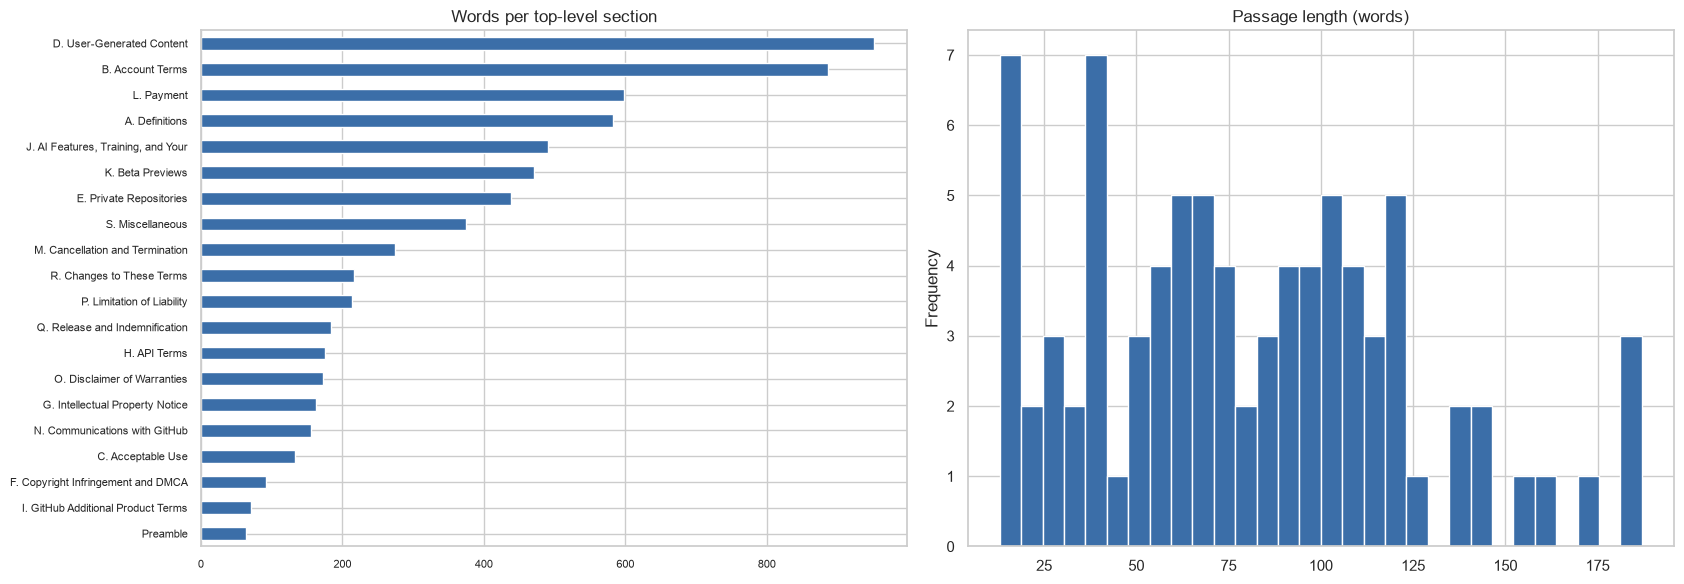

In [3]:
sw = P.groupby("top").words.sum(); sw.index = [i[:34] for i in sw.index]
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sw.sort_values().plot.barh(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Words per top-level section"); ax[0].tick_params(labelsize=8)
P.words.plot.hist(bins=30, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Passage length (words)")
plt.tight_layout(); plt.show()

**Reading it.** The cleaned document is about 7,500 words in 20 lettered sections (A to S plus the preamble) and 84 passages (median 73 words). The longest sections are User-Generated Content (951 words), Account Terms (887), Payment (598) and Definitions (582). Each section opens with a "Short version" paragraph that restates the section in plain language; that matters for retrieval, because a question can match the short version instead of the detailed clause.

## 3. What can a "first 512 tokens" summary possibly cover? (the reference's approach)
`t5-small` accepts about 512 tokens. How much of the document is inside that window, and which sections are never seen?

In [4]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
tk5 = AutoTokenizer.from_pretrained("google-t5/t5-small"); t5 = AutoModelForSeq2SeqLM.from_pretrained("google-t5/t5-small").eval()
full = " ".join(P.text)
n_tok = len(tk5(full)["input_ids"]); seen = tk5.decode(tk5(full, truncation=True, max_length=512)["input_ids"], skip_special_tokens=True)
seen_words = len(seen.split()); first_sections = []
for t_, g in P.groupby("top", sort=False):
    if g.text.iloc[0][:40] in seen: first_sections.append(t_)
print("document: %d T5 tokens | window 512 tokens = %.1f%% of the document (about %d of %d words)" % (n_tok, 512 / n_tok * 100, seen_words, len(full.split())))
print("sections whose text starts inside the window:", [s[:30] for s in first_sections], "of", P.top.nunique())

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (8675 > 512). Running this sequence through the model will result in indexing errors


document: 8675 T5 tokens | window 512 tokens = 5.9% of the document (about 353 of 6708 words)
sections whose text starts inside the window: ['Preamble', 'A. Definitions'] of 20


In [5]:
def summarise(txt, mx=90):
    b = tk5("summarize: " + txt, truncation=True, max_length=512, return_tensors="pt")
    with torch.no_grad(): g = t5.generate(**b, num_beams=4, max_length=mx, min_length=20, no_repeat_ngram_size=3, early_stopping=True)
    return tk5.decode(g[0], skip_special_tokens=True)
ref_summary = summarise(full)
sec_sum = {t_: summarise(" ".join(g.text)) for t_, g in P.groupby("top", sort=False)}
chunked = " ".join(sec_sum.values())
print("REFERENCE-STYLE SUMMARY (first 512 tokens):\n", ref_summary, "\n\nPER-SECTION SUMMARIES (first 3 of %d):" % len(sec_sum))
for k, v in list(sec_sum.items())[:3]: print(" -", k[:40], "->", v)

REFERENCE-STYLE SUMMARY (first 512 tokens):
 a "Personal Account" represents an individual User’s authorization to log in to and use the Service. "AI Feature" means any feature of GitHub or our Affiliates that uses machine learning or artificial intelligence to generate Output. 

PER-SECTION SUMMARIES (first 3 of 20):
 - Preamble -> please read this Terms of Service agreement carefully before using GitHub. we have presented these terms in a short non-binding summary followed by the full legal terms.
 - A. Definitions -> a "Personal Account" represents an individual User’s authorization to log in to and use the Service. "organizations" are shared workspaces that may be associated with a single entity or with one or more Users. the "Agreement" refers to all the terms, conditions, notices contained in this document.
 - B. Account Terms -> a human must create your Account; you must be 13 or over. you must provide a valid email address; and you may not have more than one free Account. GitHu

**Reading it.**
* The whole document is **8,675 T5 tokens; the 512-token window sees 5.9% of it**, i.e. only the beginning of the preamble and the Definitions section.
* The reference-style summary is therefore a **36-word paraphrase of two definitions** ("Personal Account", "AI Feature"): it says nothing about accounts, payment, cancellation, content or AI training, the parts a reader cares about.
* Summarising each of the 20 sections separately and joining the results gives a summary of 757 words that covers the whole document, but it is long, and the small model produces some clipped sentences ("GitHub does not target users."), which is a meaning-changing truncation of "does not target children under 13".

## 4. Question answering over the whole document: retrieval + reader
**Retrieval:** score every passage against the question with TF-IDF (word and bigram) and, separately, with **MiniLM sentence embeddings**; also a simple **hybrid** (average of the two normalised scores).
**Reader:** `distilbert-base-cased-distilled-squad` extracts an answer span from each of the top-k passages; the answer with the highest reader score is returned along with its section.
**Gold questions:** 14 answerable questions, each with an answer string that I checked appears word-for-word in the cleaned document (the code asserts it), and 4 questions the document does not answer.

In [6]:
GOLD = [
 ("What is the minimum age to use GitHub?", "You must be age 13 or older"),
 ("Can I cancel my account by sending an email?", "We are not able to cancel Accounts in response to an email or phone request"),
 ("How much notice does GitHub give before material changes to the terms take effect?", "at least 30 days prior to the change taking effect"),
 ("How long after cancellation does GitHub delete my profile and repository content?", "within 90 days of cancellation or termination"),
 ("Are payments refundable?", "is non-refundable"),
 ("How many free accounts may one person have?", "no more than one free Account"),
 ("Are accounts created by bots allowed?", "Accounts registered by \"bots\" or other automated methods are not permitted"),
 ("How can I stop GitHub using my AI inputs and outputs for model training?", "you opt out through your account settings"),
 ("How long do I have to ask for a copy of my account contents after cancellation?", "within 90 days of cancellation, termination, or downgrade"),
 ("When am I billed if I upgrade from the free plan?", "We will immediately bill you when you upgrade from the free plan"),
 ("Is the service billed in advance or in arrears for monthly and yearly plans?", "billed in advance on a monthly or yearly basis"),
 ("Does GitHub delete my contributions to other users' repositories when I cancel?", "We will not delete Content that you have contributed to other Users' repositories"),
 ("Can several people share one login?", "a single login may not be shared by multiple people"),
 ("When can the price of a subscription change?", "prices are subject to change at the end of a payment term"),
]
UNANS = ["Who is the chief executive officer of GitHub?", "What is GitHub's customer support phone number?", "Which programming languages does GitHub support?", "Does GitHub offer a discount for students?"]
full_clean = " ".join(P.text)
for q, a in GOLD: assert a in full_clean, ("gold answer not found verbatim: " + a)
for w in ["chief executive", "phone number", "programming languages", "student"]: assert w not in full_clean.lower(), ("unanswerable question may be answerable: " + w)
gold_pass = [set(np.where(P.text.str.contains(re.escape(a)))[0]) for q, a in GOLD]
print(len(GOLD), "answerable questions verified in the text |", len(UNANS), "unanswerable | passages containing each gold answer:", [len(g) for g in gold_pass])

14 answerable questions verified in the text | 4 unanswerable | passages containing each gold answer: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [7]:
from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
Pe = st.encode(list(P.text), normalize_embeddings=True)
tf = TfidfVectorizer(ngram_range=(1, 2), stop_words="english", sublinear_tf=True).fit(P.text); Pt = tf.transform(P.text)
def scores(q):
    s_t = (Pt @ tf.transform([q]).T).toarray().ravel(); s_e = Pe @ st.encode([q], normalize_embeddings=True)[0]
    z = lambda v: (v - v.mean()) / (v.std() + 1e-9); return {"TF-IDF": s_t, "MiniLM": s_e, "hybrid": z(s_t) + z(s_e)}
rows = []
for q, a in GOLD:
    sc = scores(q)
    rows.append({m: [int(any(i in set(np.argsort(-s)[:k]) for i in gold_pass[len(rows)])) for k in (1, 3, 5)] for m, s in sc.items()})
tab = pd.DataFrame({m: np.mean([r[m] for r in rows], 0) * 100 for m in ["TF-IDF", "MiniLM", "hybrid"]}, index=["hit@1", "hit@3", "hit@5"]).T
print("share of questions whose gold passage is in the top-k retrieved (%%), n = %d questions:" % len(GOLD)); print(tab.round(0).to_string())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

share of questions whose gold passage is in the top-k retrieved (%), n = 14 questions:
        hit@1  hit@3  hit@5
TF-IDF   64.0   93.0   93.0
MiniLM   86.0  100.0  100.0
hybrid   86.0   93.0  100.0


**Reading it (14 questions; the chance of a gold passage being in the top k).**
* **MiniLM sentence embeddings find the right passage first for 86% of questions and within the top 3 for all 14**; TF-IDF word matching finds it first for 64% and within the top 3 for 93%; the hybrid of the two matches MiniLM at rank 1 (86%) and reaches 100% by rank 5.
* Questions are phrased differently from the contract ("Are payments refundable?" vs "non-refundable"), so meaning-based search helps. With only 14 questions each percentage point is about 7 questions' worth of 1%, so differences of one question (7 points) are not meaningful; the clearer finding is that the top 3 almost always contain the right passage.

## 5. Add the reader and score the end-to-end answers

In [8]:
from transformers import pipeline, AutoTokenizer, AutoModelForQuestionAnswering
tokq = AutoTokenizer.from_pretrained("distilbert/distilbert-base-cased-distilled-squad"); qam = AutoModelForQuestionAnswering.from_pretrained("distilbert/distilbert-base-cased-distilled-squad").eval()
def qa(question, context, max_answer_tokens=40):
    # extractive reader: best (start, end) span, score = P(start) * P(end) over context tokens
    enc = tokq(question, context, return_tensors="pt", truncation="only_second", max_length=384, return_offsets_mapping=True)
    offs = enc.pop("offset_mapping")[0].numpy(); seq = np.array([x if x is not None else -1 for x in enc.sequence_ids(0)])
    with torch.no_grad(): o = qam(**enc)
    m = torch.from_numpy(seq == 1)
    ps = torch.softmax(o.start_logits[0].masked_fill(~m, -1e9), 0).numpy(); pe = torch.softmax(o.end_logits[0].masked_fill(~m, -1e9), 0).numpy()
    sc = np.triu(np.outer(ps, pe)); sc = np.tril(sc, max_answer_tokens)
    i, j = np.unravel_index(sc.argmax(), sc.shape)
    return {"answer": context[offs[i][0]:offs[j][1]], "score": float(sc[i, j])}
def norm(s):
    s = s.lower(); s = "".join(c for c in s if c not in set(string.punctuation)); s = re.sub(r"\b(a|an|the)\b", " ", s); return " ".join(s.split())
def f1(p, g):
    p, g = norm(p).split(), norm(g).split(); c = collections.Counter(p) & collections.Counter(g); ns = sum(c.values())
    if ns == 0: return 0.0
    pr, rc = ns / len(p), ns / len(g); return 2 * pr * rc / (pr + rc)
def answer(q, method="hybrid", k=3, strategy="best_reader"):
    s = scores(q)[method]; top = np.argsort(-s)[:k]; cands = []
    for i in top: r = qa(question=q, context=P.text[i]); cands.append({**r, "passage": int(i), "ret": float(s[i])})
    if strategy == "top1": best = cands[0]
    elif strategy == "best_reader": best = max(cands, key=lambda c: c["score"])
    else:                                                   # combined: reader confidence x softmax of the retrieval scores
        z = np.array([c["ret"] for c in cands]); w = np.exp(z - z.max()); w /= w.sum(); best = max(zip(cands, w), key=lambda t: t[0]["score"] * t[1])[0]
    best = dict(best); best["section"] = P.section[best["passage"]]; best["top_similarity"] = float(scores(q)["MiniLM"].max()); return best
def score_strategy(strategy, method="hybrid"):
    rows = []
    for j, (q, g) in enumerate(GOLD):
        r = answer(q, method=method, strategy=strategy)
        rows.append({"question": q, "pred": r["answer"], "gold": g, "score": r["score"], "section": r["section"], "EM": float(norm(r["answer"]) == norm(g)), "F1": f1(r["answer"], g),
                     "contained": float(len(norm(r["answer"])) > 0 and (norm(r["answer"]) in norm(g) or norm(g) in norm(r["answer"]))), "right_passage": float(r["passage"] in gold_pass[j])})
    return pd.DataFrame(rows)
STRATS = {"reader on top-1 passage (hybrid retrieval)": ("top1", "hybrid"), "best reader score among top-3": ("best_reader", "hybrid"),
          "reader score x retrieval weight, top-3": ("combined", "hybrid"), "reader on top-1 passage (MiniLM retrieval)": ("top1", "MiniLM")}
strat = {name: score_strategy(*v) for name, v in STRATS.items()}
ST = pd.DataFrame({k: {"exact_match_%": v.EM.mean() * 100, "token_F1": v.F1.mean(), "prediction_overlaps_gold_%": v.contained.mean() * 100, "answer_from_right_passage_%": v.right_passage.mean() * 100} for k, v in strat.items()}).T
print("end-to-end answers for the 14 answerable questions, by passage-selection strategy:"); print(ST.round(2).to_string())

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

end-to-end answers for the 14 answerable questions, by passage-selection strategy:
                                            exact_match_%  token_F1  prediction_overlaps_gold_%  answer_from_right_passage_%
reader on top-1 passage (hybrid retrieval)          21.43      0.51                       78.57                        85.71
best reader score among top-3                        7.14      0.35                       42.86                        42.86
reader score x retrieval weight, top-3              21.43      0.60                       78.57                        92.86
reader on top-1 passage (MiniLM retrieval)          14.29      0.53                       78.57                        85.71


detail for the best strategy by token F1: reader score x retrieval weight, top-3
                                                  question                                                                                            pred   F1  score
                    What is the minimum age to use GitHub?                                                                                              13 0.25   0.14
              Can I cancel my account by sending an email?                    We are not able to cancel Accounts in response to an email or phone request. 1.00   0.06
How much notice does GitHub give before material changes t                                                                                         30 days 0.36   0.58
How long after cancellation does GitHub delete my profile                                                                                          90 days 0.44   0.79
                                  Are payments refundable?                          


UNANSWERABLE questions: what the reader returns anyway
                                        question                                                answer  score  top_similarity
   Who is the chief executive officer of GitHub?                                 GitHub Support portal  0.362           0.592
 What is GitHub's customer support phone number?                                                 email  0.195           0.784
Which programming languages does GitHub support?                                 GitHub Support portal  0.226           0.546
      Does GitHub offer a discount for students? GitHub may offer subscription-based access to our API  0.217           0.620



AUC for telling answerable from unanswerable questions (n = 14 vs 4, very uncertain): reader confidence 0.77 | similarity of the best retrieved passage 0.62


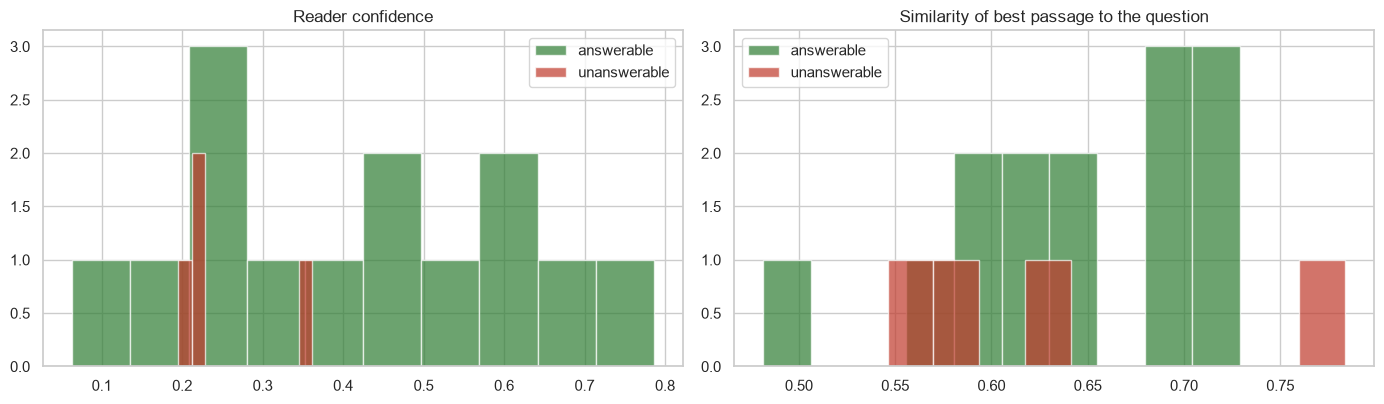

In [9]:
best_name = ST["token_F1"].idxmax(); R = strat[best_name]; print("detail for the best strategy by token F1:", best_name)
pd.set_option("display.max_colwidth", 60); print(R[["question", "pred", "F1", "score"]].assign(question=R.question.str[:58]).round(2).to_string(index=False))
strategy_, method_ = STRATS[best_name]
un = pd.DataFrame([{"question": q, **{k: v for k, v in answer(q, method=method_, strategy=strategy_).items() if k in ("answer", "score", "top_similarity")}} for q in UNANS])
print("\nUNANSWERABLE questions: what the reader returns anyway"); print(un.assign(score=un.score.round(3), top_similarity=un.top_similarity.round(3), answer=un.answer.str[:70]).to_string(index=False))
ans_read = R.score.to_numpy(); ans_sim = np.array([answer(q, method=method_, strategy=strategy_)["top_similarity"] for q, _ in GOLD])
from sklearn.metrics import roc_auc_score
y_ = [1] * len(GOLD) + [0] * len(UNANS)
print("\nAUC for telling answerable from unanswerable questions (n = %d vs %d, very uncertain): reader confidence %.2f | similarity of the best retrieved passage %.2f" % (len(GOLD), len(UNANS), roc_auc_score(y_, np.r_[ans_read, un.score.to_numpy()]), roc_auc_score(y_, np.r_[ans_sim, un.top_similarity.to_numpy()])))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(ans_read, bins=10, alpha=.7, label="answerable", color="#2e7d32"); ax[0].hist(un.score, bins=10, alpha=.7, label="unanswerable", color="#c0392b"); ax[0].legend(); ax[0].set_title("Reader confidence")
ax[1].hist(ans_sim, bins=10, alpha=.7, label="answerable", color="#2e7d32"); ax[1].hist(un.top_similarity, bins=10, alpha=.7, label="unanswerable", color="#c0392b"); ax[1].legend(); ax[1].set_title("Similarity of best passage to the question")
plt.tight_layout(); plt.show()

**Reading it (the reader is DistilBERT trained on SQuAD v1; 14 answerable questions).**
* **How the final answer is chosen matters more than the retriever.** Picking the answer with the highest *reader confidence* among the top-3 passages gives only 43% of answers from the right passage (exact match 7%, F1 0.35): the reader is often most confident about a sentence from the wrong section. Running the reader on the top-ranked passage only gives 86% right passages (F1 0.51), and **weighting the reader's confidence by the retrieval weight of its passage is best: 93% from the right passage, F1 0.60, 21% exact match**.
* Exact match is harsh here because my gold answers are whole clauses ("We are not able to cancel Accounts in response to an email or phone request") while readers return short spans ("30 days", "non-refundable", "13"). By my own reading of the 14 answers, **12 give the right fact** (the two weak ones are "how many free accounts" - the span describes machine accounts - and the AI opt-out question - "If you opt out" is only a fragment). This is a single-judge, 14-question assessment: treat it as indicative.
* **The reader cannot say "I don't know".** For the four unanswerable questions it returns a confident-looking span for every one ("GitHub Support portal" for the CEO and phone-number questions) with scores 0.20-0.36, and several *correct* answers have lower scores (the email-cancellation answer scores 0.06). So a confidence threshold cannot reject nonsense without rejecting right answers. The AUC for separating answerable from unanswerable questions is 0.77 using reader confidence and 0.62 using retrieval similarity, but with 4 negatives these figures are close to anecdotes. Production systems use a reader trained with "no answer" examples (SQuAD v2) or a verification step.

## 6. Does a summary contain the facts people ask about?
Coverage of the 14 gold facts: a fact counts as covered if at least 60% of the (normalised) words of its gold answer appear in the summary. Compared: the reference-style first-512-token summary, the per-section summaries joined, and a plain "first 120 words" baseline.

In [10]:
def covered(summary, gold):
    gw = set(norm(gold).split()); sw = set(norm(summary).split()); return len(gw & sw) / max(1, len(gw)) >= 0.6
systems = {"reference style: summary of first 512 tokens": ref_summary, "per-section summaries joined": chunked, "first 120 words of the document": " ".join(full_clean.split()[:120])}
cov_tab = pd.DataFrame({k: {"facts covered (of 14)": sum(covered(v, g) for _, g in GOLD), "summary words": len(v.split())} for k, v in systems.items()}).T; print(cov_tab.to_string())

                                              facts covered (of 14)  summary words
reference style: summary of first 512 tokens                      0             36
per-section summaries joined                                      8            757
first 120 words of the document                                   0            120


**Reading it.** Of the 14 key facts, the reference-style summary contains **0** (as does simply taking the first 120 words), while the joined per-section summaries contain **8**, at a cost of 757 words. (A fact counts as covered if at least 60% of the words of the gold answer appear in the summary; it is a crude overlap test.) A short summary of a long contract needs to be built per section or per topic; truncation to the first window is not a summary of the document.

## 7. Analysing the document itself
**Readability** (Flesch reading ease: higher = easier; roughly 60 is plain English, below 30 is very difficult) and **who is bound**: sentences where the subject is "you" with an obligation word (must, may not, shall, are responsible, agree) vs sentences where the subject is "GitHub/we" with a right word (may, reserve the right, will, can).

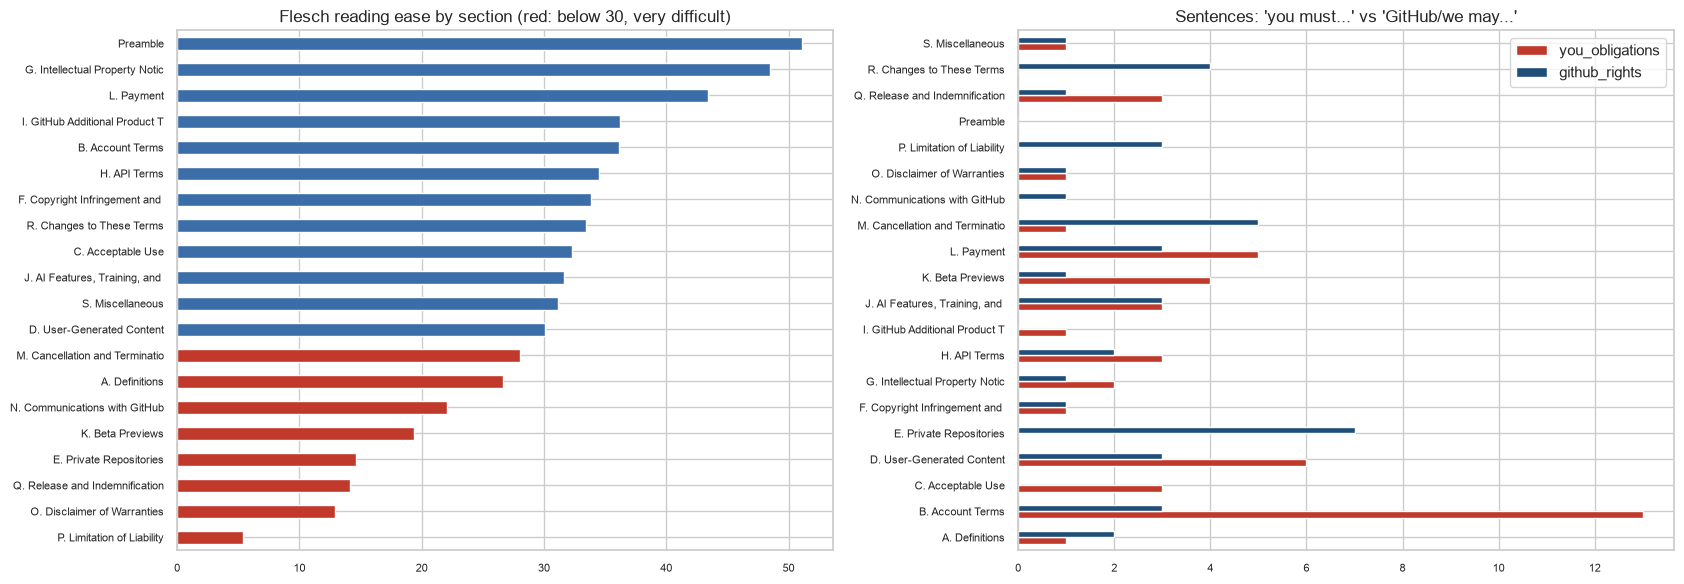

whole document: Flesch reading ease 30 | sentences binding the user: 48 | sentences stating GitHub's rights/powers: 42


In [11]:
def syll(w): return max(1, len(re.findall(r"[aeiouy]+", w.lower())))
def flesch(t):
    s = [x for x in re.split(r"[.!?]+\s", t) if x.strip()]; w = re.findall(r"[A-Za-z']+", t)
    return 206.835 - 1.015 * len(w) / max(1, len(s)) - 84.6 * sum(syll(x) for x in w) / max(1, len(w))
P["flesch"] = P.text.map(flesch)
sec = P.groupby("top").apply(lambda g: pd.Series({"words": g.words.sum(), "flesch": flesch(" ".join(g.text))}), include_groups=False)
YOU = re.compile(r"\byou (must|may not|shall|are responsible|agree|represent|warrant|are not permitted|cannot|will not|should)\b", re.I)
WE = re.compile(r"\b(github|we) (may|reserve the right|will|can|has the right|retains?|does not|do not|are not|is not|owns?)\b", re.I)
sent = [(r.top, s) for r in P.itertuples() for s in re.split(r"(?<=[.!?])\s+", r.text)]
cnt = pd.DataFrame([{"top": t_, "you_obligations": bool(YOU.search(s)), "github_rights": bool(WE.search(s))} for t_, s in sent]).groupby("top").sum()
cnt["words"] = sec.words; cnt = cnt.join(sec.flesch)
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
f = sec.flesch.sort_values(); f.index = [i[:30] for i in f.index]; f.plot.barh(ax=ax[0], color=["#c0392b" if v < 30 else "#3b6ea8" for v in f]); ax[0].set_title("Flesch reading ease by section (red: below 30, very difficult)"); ax[0].tick_params(labelsize=8)
c = cnt[["you_obligations", "github_rights"]].copy(); c.index = [i[:30] for i in c.index]; c.plot.barh(ax=ax[1], color=["#c0392b", "#1f4e79"]); ax[1].set_title("Sentences: 'you must...' vs 'GitHub/we may...'"); ax[1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()
print("whole document: Flesch reading ease %.0f | sentences binding the user: %d | sentences stating GitHub's rights/powers: %d" % (flesch(" ".join(P.text)), cnt.you_obligations.sum(), cnt.github_rights.sum()))

**Reading it.** The Flesch reading-ease of the whole document is about **30**, which is conventionally labelled "difficult" (college level), even though GitHub states it tried to make the terms clear. Counting sentences by a simple pattern, there are 48 sentences that bind the user ("you must / may not / are responsible / agree...") and 42 that state GitHub's rights ("we may / reserve the right / will..."): neither side dominates by this count. The patterns are crude regular expressions, so these counts show the method, not a legal conclusion.

## 8. Entities: who and what does the document name? (BERT NER)

In [12]:
ner = pipeline("token-classification", model="dslim/bert-base-NER", aggregation_strategy="simple", device=-1)
ents = collections.Counter()
for t_ in P.text:
    for e in ner(t_[:1500]):
        if e["score"] > .85: ents[(e["entity_group"], e["word"].strip())] += 1
E = pd.DataFrame([(k[0], k[1], v) for k, v in ents.items()], columns=["type", "entity", "mentions"]).sort_values("mentions", ascending=False)
print(E.groupby("type").head(6).sort_values(["type", "mentions"], ascending=[True, False]).to_string(index=False))
dates = re.findall(r"\b\d+ (?:days|months|years|hours)\b", full_clean); print("\ntime periods mentioned:", collections.Counter(dates).most_common(8))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


type                   entity  mentions
 LOC            United States         3
 LOC                    U. S.         2
 LOC                     U. S         1
 LOC United States of America         1
 LOC      State of California         1
 LOC            San Francisco         1
MISC                Agreement        17
MISC                   GitHub        10
MISC             Beta Preview         7
MISC              AI Features         5
MISC                        D         5
MISC                       AI         3
 ORG                   GitHub        51
 ORG                  Service        17
 ORG             Organization         8
 ORG                     GitH         5
 ORG              GitHub, Inc         2
 ORG                Microsoft         1

time periods mentioned: [('90 days', 2), ('30 days', 2), ('13 years', 1)]


**Reading it.** The NER model finds the expected people-and-places: United States (a few mentions in several spellings), State of California, San Francisco, and organisations GitHub (51 mentions), Microsoft and "GitHub, Inc". It also makes typical errors: defined terms such as "Service" (17) and "Organization" (8) are labelled as organisations, "GitH" (5) is a broken word fragment and a stray "D" is a "MISC" entity. A time-period pattern finds 90 days (twice), 30 days (twice) and 13 years: the three numbers that matter most to a user. Named-entity output is a starting point that still needs human review.

## 9. Save the pipeline pieces

In [13]:
joblib.dump({"tfidf": tf, "passages": P[["section", "text"]].to_dict("records")}, "model/gh_tos_index.joblib")
np.save("model/gh_tos_passage_embeddings.npy", Pe)
json.dump({"retrieval_hit_pct": tab.round(1).to_dict("index"), "qa": {"EM": float(R.EM.mean()), "F1": float(R.F1.mean()), "contained": float(R.contained.mean())}, "coverage": cov_tab.to_dict("index"),
           "gold": GOLD, "unanswerable": UNANS, "readers": {"retriever": "all-MiniLM-L6-v2 + TF-IDF", "reader": "distilbert/distilbert-base-cased-distilled-squad"}}, open("model/meta.json", "w"), indent=1)
print(os.listdir("model"))

['gh_tos_index.joblib', 'gh_tos_passage_embeddings.npy', 'meta.json']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Document | Google Terms of Service (PDF) | GitHub Terms of Service (public markdown, about 7,500 words) |
| Summary | t5-small on the first 512 tokens | same, plus per-section summaries: coverage of 14 key facts **0 vs 8** |
| Questions | not covered | retrieval + extractive QA scored on 14 verified questions + 4 unanswerable |
| Retrieval | n/a | MiniLM finds the right passage in the top 3 for 14 of 14 questions |
| Answers | n/a | best selection strategy: right passage 93%, F1 0.60, about 12 of 14 substantively correct (my reading) |
| Failure mode found | not tested | reader returns an answer to all unanswerable questions; confidence cannot reject them |

**What I learned.** (1) A "summary" built from the first 512 tokens is a summary of the preamble: always compute how much of the document the model sees. (2) Retrieval quality was good; the weak point was how to choose between candidate answers, and a simple combination of retrieval and reader scores helped. (3) Evaluate with questions whose answers you have verified in the source: the code asserts that each gold answer is present word-for-word. (4) Extractive readers do not abstain; design for that.

**Limits.** One document; 14 + 4 questions written by me (so the gold set is small and shares my view of the text); exact-match and F1 are rough proxies; the "answers are right" judgement is mine alone; no legal advice is implied. **Next step:** a reader that supports "no answer", a larger question set from several people, and a comparison with an LLM that must quote its source passage.